[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TheBestProEver/100micron-sim/blob/main/notebooks/07_edry_the_energy_loss.ipynb)

# 07 · $e_{dry}$: the energy a bounce loses, and how the flight can measure it

**The question.** Every sticking speed in the simulator is the undamped one times a factor $f(e_{dry})$: 1.6-2.5 at
the code's values, 1.1-4.4 over the literature ranges of section 3 (notebook 03, section 5). $e_{dry}$, the "dry" coefficient of restitution, is ASSUMED: 0.85 for silica,
0.70 for graphite. About a quarter of the silica/graphite factor rests on it (the factor 1.52 out of 6.2, i.e. 23 % of its logarithm, section 4.3). What is $e_{dry}$ physically, what
has been measured, how much does each result move with it, and can the flight's own films tell us $e_{dry}$ and the
surface energy $\gamma$?

> **How the flight measures $e_{dry}$, in brief.** The cameras film grain-grain impacts in microgravity. For each
> impact we measure the approach speed along the line between the grain centres, whether the grains stuck, and for
> a bounce the exit speed, so the restitution $e$. The model predicts where sticking stops and how $e$ rises above
> that speed, from just two numbers, $\gamma$ and $e_{dry}$; fitting it to the impacts gives both, with error bars
> (section 5). This puts requirements on the release mechanism and the cameras: speeds from two camera views (one
> camera sees only a projection, about 21 % low on average), at least 6 clean frames (12 ms at the ASSUMED design
> camera's 500 frames/s) before and after each impact, 100-200 impacts per material with a measured restitution,
> most of them near the sticking speed and a tail of faster ones at 5-10 times it (3-6 cm/s for silica, 0.2-0.4 m/s
> for graphite). This refines the answer in [docs/OVERVIEW.md](../docs/OVERVIEW.md), section 7 ("Can the experiment
> actually measure the threshold?"): a gentle (mm/s) release is what makes impacts near the threshold possible at
> all; the fast tail is what reads $e_{dry}$ almost directly.

**After this notebook you can explain**
- what $e_{dry}$ is, where the lost energy goes, and how the code turns $e_{dry}$ into a damping force;
- what the literature supports for silica (fairly well measured) and for graphite (not measured);
- how much the sticking speed, the restitution curve $e(v)$, the silica/graphite ratio and the 3-D page's outcomes
  move across that range;
- how a list of filmed impacts (speed, stuck or not, restitution) gives back $\gamma$ and $e_{dry}$ with error bars;
- why stick/bounce alone cannot separate the two, and why the restitution of bounces can;
- how many impacts the flight needs, and how to tell from the residuals whether the model itself is wrong.

**The code.** `dolle_core/inverse.py` (prediction, likelihood, fit, synthetic flights, CSV files) and
`examples/fit_flight_data.py` (fits a CSV of impacts). Everything else is the core of notebooks 01-06.

**Symbols.** $v$ approach (impact) speed along the line of centres [m/s]; $e$ restitution = separation speed / approach
speed; $e_{dry}$ the restitution of the same impact with adhesion switched off; $\gamma$ surface energy [J/m²] and
$w = 2\gamma$ the work of adhesion of two equal surfaces; $E^*$, $R^*$, $m^*$ reduced modulus [Pa], radius [m], mass
[kg]; $v_0 = \sqrt{2|U_0|/m^*}$ the undamped sticking speed and $v_{stick} = f(e_{dry})\,v_0$ the sticking speed
(notebook 03); $s = \gamma/\gamma_{cat}$ the factor on the catalogue surface energy (`dolle_core/materials.py`:
$\gamma_{cat}$ = 0.025 J/m² for silica, 0.075 J/m² for graphite; materials.py quotes 0.014-0.25 J/m² for silica in
the literature, so $s$ far from 1 is possible). "The table" in this notebook always means the restitution grid
$h(x, e_{dry})$ of section 5.2. Grains are 90-106 µm in diameter
(the flight's sieve cut) unless stated.

In [1]:
# Make the repository's packages (dolle_core, dolle_sim, and the optional extras) importable, in Colab or from a clone.
import sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules:   # in Colab: install the repository from GitHub (takes ~30 s)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/TheBestProEver/100micron-sim.git"], check=True)
else:                               # locally: the repository folder is this folder or the one above (notebooks/)
    repo = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "dolle_core").is_dir())
    sys.path.insert(0, str(repo))
    if (repo / "extras").is_dir():  # the optional v0.6 engine (extras/dolle_extras), used by the 3-D cells
        sys.path.insert(1, str(repo / "extras"))

In [2]:
import math, time
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
import dolle_core as dc                      # the readable core of the DOLL-E simulator
from dolle_core import inverse as inv        # from measured impacts back to gamma and e_dry
from dolle_core import nb_collisions as nb   # short helpers for the notebooks
from dolle_core import scenes, sim3d         # the 3-D simulation (notebook 06)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
T0 = time.perf_counter()

## 1. What $e_{dry}$ is

Two grains meet head-on at approach speed $v$ and separate at speed $e\,v$. In the frame of their centre of mass the
kinetic energy of the relative motion is $\frac12 m^*v^2$ before and $\frac12 m^*e^2v^2$ after, so a fraction
$1-e^2$ of it is lost. $e_{dry}$ is that $e$ for the same grains **with the stickiness switched off**. Where the energy
goes in a real solid:

- **internal friction** (viscoelasticity): the material does not spring back exactly along the curve it was
  compressed on, so each squeeze-and-release turns some elastic energy into heat;
- **elastic waves** radiated into the bodies, which carry energy away from the contact (small for slow impacts of
  spheres; Johnson 1985, "Contact Mechanics", ch. 11);
- **microscopic damage**: asperities (bumps on the surface) that are crushed or slide.

The adhesion hysteresis $|U_0|$ (notebook 01) is a separate loss that the model adds on top; it is what makes slow
grains stick. In the model $e_{dry}$ is one number per material pair (for two materials $\sqrt{e_1e_2}$, an ASSUMED
mixing rule, `dolle_core/pair.py`). The cell switches the stickiness off ($\gamma$ = 1e-7 J/m², as the simulator's
check `damping`) and measures $e$ at three speeds.

In [3]:
for e_dry in (0.70, 0.85, 0.95):
    e = [nb.dry_restitution("silica", e_dry, v) for v in (0.01, 0.1, 1.0)]
    print(f"e_dry = {e_dry:.2f}: non-sticky impact at 0.01 / 0.1 / 1 m/s gives e = " + " / ".join(f"{x:.4f}" for x in e)
          + f";  kinetic energy of the relative motion lost: {1 - e_dry**2:.0%}")

e_dry = 0.70: non-sticky impact at 0.01 / 0.1 / 1 m/s gives e = 0.6996 / 0.6998 / 0.6999;  kinetic energy of the relative motion lost: 51%
e_dry = 0.85: non-sticky impact at 0.01 / 0.1 / 1 m/s gives e = 0.8499 / 0.8501 / 0.8501;  kinetic energy of the relative motion lost: 28%
e_dry = 0.95: non-sticky impact at 0.01 / 0.1 / 1 m/s gives e = 0.9500 / 0.9500 / 0.9500;  kinetic energy of the relative motion lost: 10%


**Why this happens.** Without adhesion the model returns $e_{dry}$ at every speed, to about 1e-3: the damping is
built so that the restitution does not depend on speed (next section). An $e_{dry}$ of 0.85 means 28 % of the
energy of the relative motion is lost in every impact, 0.70 means 51 %. That loss acts while the contact is being
squeezed and released, so it also decides how much energy is left to pull the grains out of the adhesive well:
lower $e_{dry}$, more sticking.

## 2. How the code turns $e_{dry}$ into a damping force

Notebook 01 (section 3) derives this in full; here is the chain in four steps.

1. **A linear spring with a dashpot.** $m^*\ddot x + c\dot x + kx = 0$, starting at $x = 0$ with speed $v$. With
   $\omega_0 = \sqrt{k/m^*}$ and the damping ratio $\zeta = c/(2\sqrt{km^*})$ the solution is
   $x = \frac{v}{\omega_d}e^{-\zeta\omega_0t}\sin\omega_dt$, $\omega_d = \omega_0\sqrt{1-\zeta^2}$. Contact ends at
   $t = \pi/\omega_d$, with speed $v\,e^{-\pi\zeta/\sqrt{1-\zeta^2}}$, so
   $$e = \exp\!\Big(-\frac{\pi\zeta}{\sqrt{1-\zeta^2}}\Big)\quad\Longleftrightarrow\quad
   \zeta = \frac{-\ln e}{\sqrt{(\ln e)^2+\pi^2}} \equiv -\beta .$$
2. **The Hertz contact is a spring whose stiffness grows with the patch.** From $F = \frac43E^*\sqrt{R^*}\delta^{3/2}$,
   $k = dF/d\delta = 2E^*\sqrt{R^*\delta} = 2E^*a$ ($a$ the contact patch radius). Putting this $k$ into the dashpot
   $c = 2\zeta\sqrt{km^*}$ gives a force $\propto \sqrt{a}\,\dot\delta$. The published form (Tsuji, Tanaka & Ishida 1992,
   Powder Technol. 71, 239, as written by DEM codes) carries a factor $\sqrt{5/6}$:
   $$F_{damp} = c_d\sqrt{a}\;\dot\delta,\qquad c_d = -2\sqrt{5/6}\;\beta(e_{dry})\;\sqrt{2E^*m^*}
   \quad[\mathrm{kg\,m^{-1/2}\,s^{-1}}].$$
3. **Why $e$ then does not depend on speed or material.** Without adhesion the equation is
   $m^*\ddot\delta = -K\delta^{3/2} - c_dR^{*1/4}\delta^{1/4}\dot\delta$, $K = \frac43E^*\sqrt{R^*}$. Measure $\delta$ in units
   of $D$ (set by the speed) and time in units of $T$ with $m^*D/T^2 = KD^{3/2}$; the damping term becomes
   $[c_dR^{*1/4}/\sqrt{Km^*}]\,x^{1/4}\dot x$, and with the $c_d$ above the bracket is $\sqrt5\,|\beta|$: no $D$, no
   material. So $e$ is a function of $e_{dry}$ alone, and the calibration can be checked once.
4. **The calibration.** Step 1 is exact only for a linear spring; for the Hertz spring the factor $\sqrt{5/6}$ is the
   standard approximation. The cell finds, for several $e_{dry}$, the prefactor that would return $e_{dry}$ exactly
   (`nb.calibrated_prefactor`, bisection with the core's own collision loop) and the error the code makes with
   $\sqrt{5/6}$.

With adhesion on, the code evaluates $a$ as the JKR patch radius, so the damping also acts while the neck is
stretched ($\delta < 0$, the grains already past zero overlap but still held by the neck). That is the simulator's
own adaptation (`dolle_core/damping.py`; PROVENANCE.md, "Viscoelastic damping"), and it is part of what links
$e_{dry}$ to $f$. So an $e_{dry}$ fitted to flight data is a parameter of this damping model (section 5).

In [4]:
print(f"sqrt(5/6) = {math.sqrt(5/6):.5f}")
worst = 0.0
for e_dry in (0.5, 0.7, 0.85, 0.95):
    k = nb.calibrated_prefactor(e_dry)
    got = nb.dry_restitution("silica", e_dry, 0.1)
    worst = max(worst, abs(got - e_dry))
    print(f"e_dry = {e_dry:4.2f}: beta = {dc.damping_beta(e_dry):+.4f}; prefactor that returns e_dry exactly {k:.5f}; "
          f"with sqrt(5/6) the code returns {got:.5f}")
print(f"largest |e - e_dry| with sqrt(5/6): {worst:.1e}")

sqrt(5/6) = 0.91287
e_dry = 0.50: beta = -0.2155; prefactor that returns e_dry exactly 0.91214; with sqrt(5/6) the code returns 0.49972
e_dry = 0.70: beta = -0.1128; prefactor that returns e_dry exactly 0.91232; with sqrt(5/6) the code returns 0.69985
e_dry = 0.85: beta = -0.0517; prefactor that returns e_dry exactly 0.91356; with sqrt(5/6) the code returns 0.85011
e_dry = 0.95: beta = -0.0163; prefactor that returns e_dry exactly 0.91282; with sqrt(5/6) the code returns 0.95000
largest |e - e_dry| with sqrt(5/6): 2.8e-04


**Why this happens.** The exact prefactor is within about 0.1 % of $\sqrt{5/6}$ for every $e_{dry}$, so the code's
damping returns the $e_{dry}$ it is given to better than 1e-3. That error is far below anything a flight
measurement could detect.

> **Why this choice: one speed-independent number.**
> *Alternatives:* a constant dashpot $F = c\dot\delta$ (its restitution changes with speed, because the Hertz contact
> time does); the viscoelastic law of Brilliantov, Spahn, Hertzsch & Pöschel (1996, Phys. Rev. E 53, 5382), where
> $1-e$ grows as $v^{1/5}$ (Kuwabara & Kono 1987, Jpn. J. Appl. Phys. 26, 1230), which needs a dissipation constant
> nobody has measured for these grains. *Evidence:* the measurements of section 3 do not show a clean $v^{1/5}$ law
> at the flight's cm/s speeds (glass in vacuum loses MORE at 0.01 m/s than at 1 m/s), so a single number is the
> honest minimum. *Consequence:* the flight can test it, because the model then predicts the whole $e(v)$ curve
> from two numbers (section 5).

## 3. What has been measured

A measured restitution stands in for $e_{dry}$ only if the impact is (1) fast enough that adhesion no longer matters
(in the model $e$ reaches $e_{dry}$ only well above $v_{stick}$, section 4.2), (2) slow enough that the grains do not
dent, and (3) made with similar materials, smooth spheres and no gas (air cushions grains of a few hundred µm and
lowers $e$; Drücker et al. 2016). Grades: **A** close to $e_{dry}$; **B** one condition differs, bias direction known;
**C** adhesion, shape, charge or gas contaminate it, a bound only; **D** qualitative.

| material, size | target | speed | environment | measured $e$ | source | grade |
|---|---|---|---|---|---|---|
| soda-lime glass, 3.18 mm | same sphere | 0.3-1.7 m/s | air | 0.97 ± 0.01 | Foerster, Louge, Chang & Allia 1994, Phys. Fluids 6, 1108 | B |
| glass beads 0.1-0.4 mm (and up to 4 mm) | steel plate | about 2 m/s | 0.1 mbar | about 0.9 for all sizes | Drücker, Krautstrunk, Paulick, Saleh, Morgeneyer & Kwade 2016, J. Vis. Exp. 109, e53299 | A/B |
| glass and basalt, about 1 mm | room-temperature glass plate | about 1 m/s | not stated in the abstract | about 0.9 (particles below 900 K; the paper is about heated particles) | Bogdan, Teiser, Fischer, Kruss & Wurm 2019, Icarus 319, 133 | B |
| silver-coated glass, 1-30 µm | polished steel | 2-25 m/s | air | adhesion gone above about 15 m/s; plateau 0.87-0.90 at 15 m/s (plateau values not checked against the paper) | Dunn, Brach & Caylor 1995, Aerosol Sci. Technol. 23, 80 | B |
| silica spheres 1.2 / 0.5 µm (diameters or radii: not checked) | polished silica | 1-10 m/s | vacuum | about 0.7 / 0.5 (not checked against the paper) | Poppe, Blum & Henning 2000, ApJ 533, 454 | C (adhesion still active) |
| glass spheres about 1 mm, free-floating | each other | below 2 cm/s | orbital microgravity, sealed trays | tray means 0.55-0.94; sticking from about 1 cm/s | Brisset, Miletich, Metzger, Rascon, Dove & Colwell 2019, A&A 631, A35 | C |
| smooth glass beads 10 mm | same | 1 m/s / 0.01 m/s | vacuum | about 1 (1.01, a systematic error from slight rotation before the collision, per the survey) / 0.93 | Beger 2012, summarised by Güttler, Heißelmann, Blum & Krijt 2012, arXiv:1204.0001 | B/C |
| natural graphite flakes, µm | wall | 0.5-12 m/s | air | rises then falls with speed; numbers not retrieved | Zhang et al. 2020, Prog. Nucl. Energy 125, 103391 | D |
| irregular diamond, 0.14-1.5 µm | polished silica | up to 50 m/s | vacuum | below 0.1 (shape and adhesion) | Poppe, Blum & Henning 2000 | C/D |

All the A/B rows are mm-size glass (or glass on steel) at m/s speeds; none is 100 µm silica on silica in vacuum at
cm/s. Carrying them over to the flight powder is a judgement; the ground drop test at the end of this section is what
would make it a measurement. (An earlier draft also listed 2.97 mm glass beads, 0.922 / 0.972; its source could not
be identified, so it was removed.)

No measured restitution was found for graphite spheres, glassy-carbon spheres or carbonaceous dust analogues under
conditions that map onto $e_{dry}$. The cell collects the numbers used below.

In [5]:
EDRY_LIT = [   # (material, value or (low, high), what, source)
    ("silica", 0.97, "3.18 mm glass on glass, air", "Foerster et al. 1994"),
    ("silica", 0.9, "0.1-0.4 mm glass on steel, 0.1 mbar, 2 m/s", "Druecker et al. 2016"),
    ("silica", 0.9, "1 mm glass on glass, 1 m/s", "Bogdan et al. 2019"),
    ("silica", (0.87, 0.90), "10 um glass on steel, plateau at 15 m/s (not checked)", "Dunn, Brach & Caylor 1995"),
    ("silica", (0.5, 0.7), "0.5 / 1.2 um silica, vacuum, adhesion on (bound; not checked)", "Poppe, Blum & Henning 2000"),
    ("silica", (0.55, 0.94), "mm glass, orbital microgravity, tray means (bound)", "Brisset et al. 2019"),
    ("silica", (0.93, 1.0), "10 mm glass, vacuum, at 0.01 / 1 m/s (1.01 = systematic error)", "Beger 2012 in Guettler et al. 2012"),
]
for mat, val, what, src in EDRY_LIT:
    print(f"{mat:8s} {str(val):12s} {what:66s} {src}")
RANGES = {   # material: (central, low, high, basis)
    "silica":   (0.90, 0.80, 0.97, "measured cluster 0.87-0.97; low end widened for rough powder (judgement)"),
    "graphite": (0.70, 0.50, 0.90, "no measurement: ASSUMED central value, range a judgement"),
    "glassy carbon spheres": (None, 0.85, 0.95, "judgement: a hard, glass-like solid"),
}
print()
for k, (c, lo, hi, why) in RANGES.items():
    print(f"{k:22s} central {c if c is not None else '-':>4}  range {lo:.2f}-{hi:.2f}   {why}")
print(f"code's values (dolle_core/materials.py): silica {dc.get_material('silica').e_dry}, "
      f"graphite {dc.get_material('graphite').e_dry}")

silica   0.97         3.18 mm glass on glass, air                                        Foerster et al. 1994
silica   0.9          0.1-0.4 mm glass on steel, 0.1 mbar, 2 m/s                         Druecker et al. 2016
silica   0.9          1 mm glass on glass, 1 m/s                                         Bogdan et al. 2019
silica   (0.87, 0.9)  10 um glass on steel, plateau at 15 m/s (not checked)              Dunn, Brach & Caylor 1995
silica   (0.5, 0.7)   0.5 / 1.2 um silica, vacuum, adhesion on (bound; not checked)      Poppe, Blum & Henning 2000
silica   (0.55, 0.94) mm glass, orbital microgravity, tray means (bound)                 Brisset et al. 2019
silica   (0.93, 1.0)  10 mm glass, vacuum, at 0.01 / 1 m/s (1.01 = systematic error)     Beger 2012 in Guettler et al. 2012

silica                 central  0.9  range 0.80-0.97   measured cluster 0.87-0.97; low end widened for rough powder (judgement)
graphite               central  0.7  range 0.50-0.90   no measurement: ASSUMED 

> **Why this choice: these ranges.**
> - **Silica: 0.90, range 0.80-0.97.** Measured: smooth glass, at speeds where adhesion and denting do not matter,
>   gives 0.87-0.97 (rows above graded A/B). Judgement: carrying mm glass-on-glass and glass-on-steel numbers to
>   100 µm silica on silica, and widening the low end to 0.80 because the flight powder is not chosen and worn or
>   etched surfaces lose up to about 0.05 more. The code's 0.85 lies inside, below the centre.
> - **Graphite: 0.70, range 0.50-0.90, ASSUMED.** Nothing measured maps onto $e_{dry}$. Graphite grains are layered,
>   often porous flakes, which plausibly dissipate more than glass (judgement). If the carbon is glassy-carbon
>   spheres, 0.85-0.95 is more plausible (judgement: a hard, glass-like solid).
> - *The decisive measurement:* drop the actual flight powders in vacuum (at most 0.1 mbar) onto a polished plate of
>   the same material at 0.1-1 m/s, filmed at high speed (the method of Drücker et al. 2016). There adhesion is
>   negligible or small, so the measured $e$ is $e_{dry}$ (section 4.2 gives the multiples of $v_{stick}$).

## 4. How much every result moves with $e_{dry}$

### 4.1 The sticking speed: $v_{stick} = f(e_{dry})\,v_0$

$f$ is the same for every material and size (notebook 03, section 5). `inverse.threshold_factor` reads it from a
table computed once with the core's collision loop (section 5.2); the cell checks the table against
`dc.damping_factor` and turns $f$ into sticking speeds of two 50 µm radius grains.

In [6]:
for e in (0.5, 0.7, 0.85, 0.95):
    print(f"f({e}) table {inv.threshold_factor(e):.4f}, direct bisection {dc.damping_factor(e, n_sub=300, tol=1e-5):.4f}")
r = 50e-6
v0 = {m: dc.undamped_sticking_speed(dc.make_pair(m, r, m, r)) for m in ("silica", "graphite")}
print("\ne_dry    : " + "  ".join(f"{e:5.2f}" for e in (0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.98)))
print("f(e_dry)  : " + "  ".join(f"{inv.threshold_factor(e):5.2f}" for e in (0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.98)))
for m in v0:
    c, lo, hi, _ = RANGES[m]
    vs = lambda e: inv.threshold_factor(e) * v0[m] * 1e3
    print(f"{m:8s}: v0 = {v0[m]*1e3:.2f} mm/s; v_stick {vs(dc.get_material(m).e_dry):.2f} mm/s at the code's e_dry, "
          f"{vs(hi):.2f} to {vs(lo):.2f} mm/s over the range {lo}-{hi} (factor {vs(lo)/vs(hi):.2f})")
for e in (0.80, 0.90, 0.97):
    print(f"silica at e_dry = {e:.2f} instead of 0.85: sticking speeds x{inv.threshold_factor(e)/inv.threshold_factor(0.85):.3f}")

f(0.5) table 4.4389, direct bisection 4.4389
f(0.7) table 2.4611, direct bisection 2.4611
f(0.85) table 1.6148, direct bisection 1.6148
f(0.95) table 1.1891, direct bisection 1.1891

e_dry    :  0.50   0.60   0.70   0.75   0.80   0.85   0.90   0.95   0.98
f(e_dry)  :  4.44   3.27   2.46   2.14   1.86   1.61   1.39   1.19   1.07
silica  : v0 = 3.83 mm/s; v_stick 6.18 mm/s at the code's e_dry, 4.26 to 7.13 mm/s over the range 0.8-0.97 (factor 1.67)
graphite: v0 = 15.58 mm/s; v_stick 38.33 mm/s at the code's e_dry, 21.69 to 69.14 mm/s over the range 0.5-0.9 (factor 3.19)
silica at e_dry = 0.80 instead of 0.85: sticking speeds x1.153
silica at e_dry = 0.90 instead of 0.85: sticking speeds x0.862
silica at e_dry = 0.97 instead of 0.85: sticking speeds x0.689


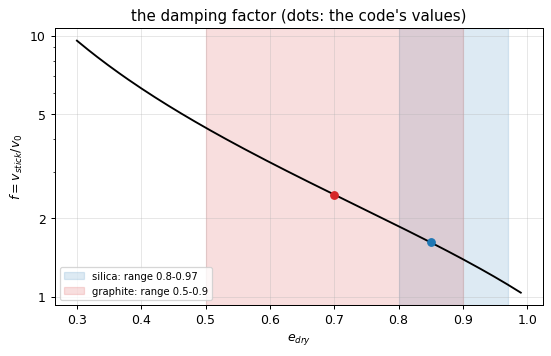

In [7]:
eg = np.linspace(0.30, 0.99, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(eg, inv.threshold_factor(eg), "k-")
for m, col in (("silica", "C0"), ("graphite", "C3")):
    c, lo, hi, _ = RANGES[m]
    ax.axvspan(lo, hi, color=col, alpha=0.15, label=f"{m}: range {lo}-{hi}")
    ax.plot(dc.get_material(m).e_dry, inv.threshold_factor(dc.get_material(m).e_dry), "o", color=col)
ax.set_xlabel("$e_{dry}$"); ax.set_ylabel("$f = v_{stick}/v_0$"); ax.set_yscale("log"); nb.plain_log_axis(ax, "y")
ax.set_title("the damping factor (dots: the code's values)"); ax.legend(fontsize=8); plt.show()

**Why this happens.** $f$ climbs steeply as $e_{dry}$ falls: from 1.39 at 0.90 to 2.46 at 0.70 and 4.44 at 0.50.
Over silica's range (0.80-0.97) the silica sticking speed moves by a factor of 1.67; over graphite's (0.50-0.90) the
graphite one by a factor of 3.19. Moving silica from the code's 0.85 to the literature's central 0.90 lowers every
silica sticking speed by 14 %.

**Why 0.85 raises the sticking speed by 61 %, not by 1/0.85 = 1.18.** At the sticking speed the incoming energy
just pays for the losses: $\frac12 m^*v_{stick}^2 = |U_0| + E_{damp}$, with $|U_0| = \frac12 m^*v_0^2$ the adhesion
loss (notebook 03; taking it to be the same with damping on). Dividing by $\frac12 m^*v_{stick}^2$:
$$\frac{E_{damp}}{\frac12 m^*v_{stick}^2} = 1 - \frac{1}{f(e_{dry})^2}.$$
The cell evaluates it.

In [8]:
for e in (0.95, 0.90, 0.85, 0.70):
    f = inv.threshold_factor(e)
    print(f"e_dry = {e:.2f}: f = {f:.2f}; damping takes {1 - 1/f**2:.0%} of the incoming energy at the sticking speed, "
          f"against {1 - e**2:.0%} in a non-sticky impact")

e_dry = 0.95: f = 1.19; damping takes 29% of the incoming energy at the sticking speed, against 10% in a non-sticky impact
e_dry = 0.90: f = 1.39; damping takes 48% of the incoming energy at the sticking speed, against 19% in a non-sticky impact
e_dry = 0.85: f = 1.61; damping takes 62% of the incoming energy at the sticking speed, against 28% in a non-sticky impact
e_dry = 0.70: f = 2.46; damping takes 83% of the incoming energy at the sticking speed, against 51% in a non-sticky impact


**Why this happens.** At $e_{dry}$ = 0.85 the damping takes about 62 % of the incoming energy at the sticking speed,
more than twice the 28 % it takes in a non-sticky impact. Two reasons: at snap-on the adhesive well pulls the grains
into contact, so their speed inside the contact (on which the damping force $\propto\dot\delta$ acts) is set by the well,
not by the slow approach speed; and the damping keeps acting while the neck is stretched on the way out (section 2).
So $1/e_{dry}$ is the wrong estimate; $f$ has to be computed (or read from the table).

### 4.2 The restitution curve $e(v)$

The model's $e(v)$ depends on $v$ only through $x = v/v_0$ and on $e_{dry}$ (section 5.2), so one plot in units of
$v_{stick}$ shows every material. Left: silica pairs at four values of $e_{dry}$ in mm/s; right: $e/e_{dry}$ against
$v/v_{stick}$.

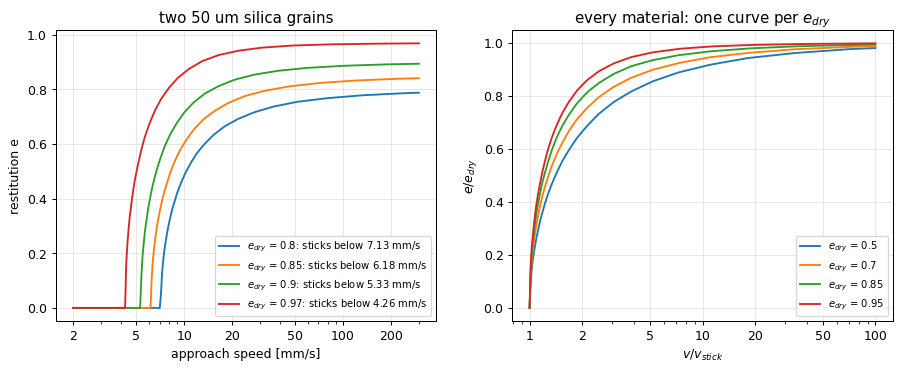

e/e_dry at v/v_stick =      1.5     3      5     10    100
   e_dry = 0.50:       0.536  0.771  0.850  0.910  0.979
   e_dry = 0.70:       0.606  0.829  0.894  0.940  0.987
   e_dry = 0.85:       0.669  0.878  0.931  0.964  0.993
   e_dry = 0.95:       0.716  0.918  0.961  0.983  0.997
silica: 5 to 10 v_stick = 31 to 62 mm/s (code's e_dry)
graphite: 5 to 10 v_stick = 192 to 383 mm/s (code's e_dry)


In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
for e in (0.80, 0.85, 0.90, 0.97):
    c = inv.curves(1.0, e, "silica", r1=r, r2=r, speeds=np.geomspace(2e-3, 0.3, 300))
    a1.semilogx(c["v"] * 1e3, c["e"], label=f"$e_{{dry}}$ = {e}: sticks below {c['v_stick']*1e3:.2f} mm/s")
a1.set_xlabel("approach speed [mm/s]"); a1.set_ylabel("restitution e"); a1.set_title("two 50 um silica grains")
a1.legend(fontsize=8)
xs = np.geomspace(1.0, 100, 300)
for e in (0.5, 0.7, 0.85, 0.95):
    a2.semilogx(xs, inv.restitution_of_x(xs * inv.threshold_factor(e), e) / e, label=f"$e_{{dry}}$ = {e}")
a2.set_xlabel("$v / v_{stick}$"); a2.set_ylabel("$e / e_{dry}$"); a2.set_title("every material: one curve per $e_{dry}$")
nb.plain_log_axis(a1, "x"); nb.plain_log_axis(a2, "x")
a2.legend(fontsize=8); plt.show()
print("e/e_dry at v/v_stick =      1.5     3      5     10    100")
for e in (0.5, 0.7, 0.85, 0.95):
    print(f"   e_dry = {e:4.2f}:       " + "  ".join(f"{float(inv.restitution_of_x(x * inv.threshold_factor(e), e)) / e:5.3f}"
                                             for x in (1.5, 3, 5, 10, 100)))
for m in ("silica", "graphite"):
    vs = inv.threshold_factor(dc.get_material(m).e_dry) * v0[m]
    print(f"{m}: 5 to 10 v_stick = {5 * vs * 1e3:.0f} to {10 * vs * 1e3:.0f} mm/s (code's e_dry)")

**Why this happens.** Just above $v_{stick}$ the grains barely escape, so $e$ starts at zero and rises steeply (as
the square root of the excess energy). Far above, the adhesion loss $|U_0|$ is a small part of the incoming energy and
$e \to e_{dry}$. The approach is slow: at 5 $v_{stick}$ the restitution is still 0.85-0.96 of $e_{dry}$ and at
10 $v_{stick}$ 0.91-0.98 (for $e_{dry}$ = 0.50-0.95; lower $e_{dry}$ approaches more slowly). So **reading $e_{dry}$ directly off bounces needs
impacts at 5-10 $v_{stick}$**, i.e. 3-6 cm/s for silica and 0.2-0.4 m/s for graphite. Below that, $e_{dry}$ can
still be fitted, but only through the model's shape of the curve (section 5).

### 4.3 Silica against graphite

The ratio of the two sticking speeds is (material constants) × $f(e_{graphite})/f(e_{silica})$. The first factor is
fixed by published constants (notebook 03, section 6); the second spans whatever the two $e_{dry}$ do.

undamped ratio (material constants only): 4.070
with the code's e_dry (graphite 0.70, silica 0.85): 6.20
with the literature's centres (graphite 0.70, silica 0.90): 7.19
extremes over the ranges: 3.04 (graphite 0.90, silica 0.80) to 16.25 (graphite 0.50, silica 0.97); equal e_dry: 4.07
share of ln(ratio) carried by the e_dry values at the code's numbers: 23%


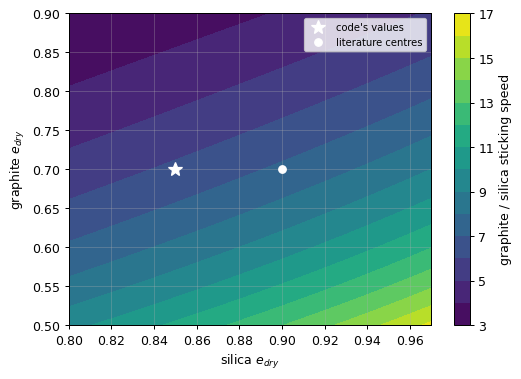

In [10]:
mat_ratio = v0["graphite"] / v0["silica"]
print(f"undamped ratio (material constants only): {mat_ratio:.3f}")
ratio = lambda eg_, es_: mat_ratio * inv.threshold_factor(eg_) / inv.threshold_factor(es_)
print(f"with the code's e_dry (graphite 0.70, silica 0.85): {ratio(0.70, 0.85):.2f}")
print(f"with the literature's centres (graphite 0.70, silica 0.90): {ratio(0.70, 0.90):.2f}")
print(f"extremes over the ranges: {ratio(0.90, 0.80):.2f} (graphite 0.90, silica 0.80) to {ratio(0.50, 0.97):.2f} "
      f"(graphite 0.50, silica 0.97); equal e_dry: {mat_ratio:.2f}")
share = math.log(ratio(0.70, 0.85) / mat_ratio) / math.log(ratio(0.70, 0.85))
print(f"share of ln(ratio) carried by the e_dry values at the code's numbers: {share:.0%}")
es_, eg_ = np.meshgrid(np.linspace(0.80, 0.97, 60), np.linspace(0.50, 0.90, 60))
fig, ax = plt.subplots(figsize=(6.5, 4.5))
cs = ax.contourf(es_, eg_, ratio(eg_, es_), levels=14, cmap="viridis")
plt.colorbar(cs, label="graphite / silica sticking speed")
ax.plot(0.85, 0.70, "w*", ms=12, label="code's values"); ax.plot(0.90, 0.70, "wo", label="literature centres")
ax.set_xlabel("silica $e_{dry}$"); ax.set_ylabel("graphite $e_{dry}$"); ax.legend(fontsize=8); plt.show()

**Why this happens.** The published constants alone give graphite a 4.07 times higher sticking speed; the code's
$e_{dry}$ values raise that to 6.20 (23 % of the logarithm of the ratio rests on $e_{dry}$). With the literature's
central silica value it becomes 7.19. Over the two ranges the ratio could be anywhere from 3.04 to 16.3. The
direction (graphite sticks more easily) survives every combination; the size of the factor does not, so the
factor "about 6" should be quoted with $e_{dry}$ named as its main uncertainty.

### 4.4 The 3-D page's outcomes

The 3-D page (notebook 06) runs a silica tubule and a graphite tubule from the same start: 100 grains in a 2 mm cloud
with speeds $|N(15, 7.5)|$ mm/s (ASSUMED, `scenes.START_SOURCES`). The cell reruns each tubule with other $e_{dry}$
values (`inv.override_material` changes the material table for the duration of the run; the walls keep their own
ASSUMED 0.8, so grain-wall pairs get $\sqrt{0.8\,e_{dry}}$).

In [11]:
start = scenes.two_tubule_start()
rows = []
for mat, values in (("silica", (0.80, 0.90, 0.97)), ("graphite", (0.50, 0.70, 0.90))):
    for e in values:
        with inv.override_material(mat, e_dry=e):
            s = scenes.run_tubule(start, mat, t_end=12.0)
        sm = sim3d.summary(s)
        rows.append((mat, e, sm["counts"]["stick"], sm["counts"]["bounce"], sm["counts"]["wall_stick"],
                     sm["counts"]["wall_bounce"], sm["largest_clump"], sm["clump_sizes_at_end"].get("1", 0)))
print(f"{'tubule':9s} {'e_dry':>5s} | grain-grain: {'stick':>5s} {'bounce':>6s} | wall: {'stick':>5s} {'bounce':>6s} | "
      f"largest clump  single grains at end")
for row in rows:
    print(f"{row[0]:9s} {row[1]:5.2f} |              {row[2]:5d} {row[3]:6d} |       {row[4]:5d} {row[5]:6d} | "
          f"{row[6]:13d}  {row[7]:5d}")

tubule    e_dry | grain-grain: stick bounce | wall: stick bounce | largest clump  single grains at end
silica     0.80 |                  8     14 |          97    129 |             2     96
silica     0.90 |                  3     17 |          96    171 |             2     98
silica     0.97 |                  4     20 |          90    212 |             3     95
graphite   0.50 |                 17      0 |          84     10 |             3     72
graphite   0.70 |                 17      0 |          84     19 |             3     72
graphite   0.90 |                 15      3 |          86     39 |             3     75


**Why this happens.** The start was chosen so that its speeds (median about 15 mm/s) lie above silica's sticking
speed and below graphite's, and that stays true across both ranges: graphite's grain-grain impacts nearly all
stick (15-17 of 17-18) and most of silica's bounce. Silica at 0.80 sticks a little more often (8 of 22 against 3-4
of 20-24), as its sticking speed rises from about 4.3 to 7.1 mm/s, but with about 20 grain-grain impacts per run and
runs that diverge once one outcome differs, differences of a few counts are probably within run-to-run scatter (not measured here: each tubule and $e_{dry}$ was run once). The clear
trend is at the walls: the number of wall bounces rises with $e_{dry}$ in both tubules (129 to 212 for silica, 10
to 39 for graphite), because the grain-wall sticking speeds fall. So within these ranges $e_{dry}$ changes **how
long grains keep flying** more than it changes the page's grain-grain picture (largest clumps of 2-3 grains in
every run).

## 5. From flight data back to $e_{dry}$ and $\gamma$

Each filmed impact gives a measured speed $v_m$, stuck or bounced, and for a bounce a measured restitution $e_m$. The
model has two numbers the flight can test: $s = \gamma/\gamma_{cat}$ and $e_{dry}$. This section builds the fit in
`dolle_core/inverse.py` step by step and tests it on synthetic flights, where the true answer is known.

### 5.1 The measurement errors

**Two camera views.** The speeds in this section are the normal components (along the line of centres) in 3-D,
which needs two orthogonal views (`dolle_sim/analysis.py`, `synthetic_camera`; PROVENANCE.md: one camera cannot
recover it). With one camera an impact whose line of centres makes an angle $\theta$ with the view axis shows
$v\sin\theta$; for random orientations the mean of $\sin\theta$ is $\pi/4$, so speeds come out about 21 % low on
average and $\gamma$ (which scales as $v_{stick}^{6/5}$) about 25 % low, more than the ±10 % target below. Single-camera
data would have to be corrected with the projected centre separation at contact, $(r_1+r_2)\sin\theta$ (which needs
measured radii), or restricted to impacts close to the image plane.

The camera (ASSUMED design camera of `configs/mission_quarter_deck.json`) finds grain centres to $\sigma_x$ in each frame and fits a straight line to $k$ frames at fps frames/s. A
least-squares slope through $k$ equally spaced points has error $\sigma_x\,\mathrm{fps}\sqrt{12/(k(k^2-1))}$, and a
relative velocity (two grains) $\sqrt2$ times that (`dolle_sim/analysis.py`, `synthetic_camera`). On top of it the
line of centres is found from two centroids about 100 µm apart, so its direction is uncertain by about
$\delta\theta = \sqrt2 \times 5\ \mu m/100\ \mu m$ = 0.07 rad. Projecting the relative velocity (normal part $v_n$,
tangential part $v_t$) on a direction turned by $\delta\theta$ gives $v_n\cos\delta\theta + v_t\sin\delta\theta \approx
v_n + v_t\,\delta\theta$, so $\delta v_n/v_n = \delta\theta\,\tan\alpha$ with $\alpha$ the impact angle from head-on
($\tan\alpha = v_t/v_n$). For random impact parameters the median $\tan\alpha$ is 1 (a 7 % error), with a heavy tail
for grazing impacts; we model it as a relative error of 5 %, i.e. a typical $v_t/v_n$ of 0.7 (ASSUMED). So
$\sigma_v(v) = \sqrt{\sigma_{abs}^2 + (0.05\,v)^2}$. The exit speed is measured the same way and $e_m = v_{out,m}/v_m$.

Limits of this error model: the direction error is common to the incoming and the outgoing speed of one impact and
scales with $v_t$, but the model treats the two errors as independent and proportional to $v$ (probably conservative
for $e$); and if restitutions are measured preferentially for clear, fast bounces, that selection is not modelled. The
synthetic flights below are made with the same assumptions, so they test the fit, not these assumptions. Noise in
both speeds can push a measured $e$ above 1 (or, for a very slow exit, below 0); such values are expected and must
not be clipped or dropped.

In [12]:
err = inv.SpeedError()
print(f"ASSUMED design camera (500 frames/s, 5 um, 6 frames): sigma_abs = {inv.camera_speed_error()*1e3:.3f} mm/s; sigma_rel = {err.sigma_rel}")
for v in (0.005, 0.02, 0.05, 0.2):
    e = 0.8
    se = math.hypot(float(err.sigma(e * v)), e * float(err.sigma(v))) / v
    print(f"v = {v*1e3:5.0f} mm/s: sigma_v = {float(err.sigma(v))*1e3:.2f} mm/s ({float(err.sigma(v))/v:.0%}); "
          f"error of a measured e = 0.8: about {se:.3f}")
print(f"spread of ln v0 when the radii are not measured (90-106 um sieve cut): {inv.size_scatter_ln_v0():.3f}")

ASSUMED design camera (500 frames/s, 5 um, 6 frames): sigma_abs = 0.845 mm/s; sigma_rel = 0.05
v =     5 mm/s: sigma_v = 0.88 mm/s (18%); error of a measured e = 0.8: about 0.224
v =    20 mm/s: sigma_v = 1.31 mm/s (7%); error of a measured e = 0.8: about 0.078
v =    50 mm/s: sigma_v = 2.64 mm/s (5%); error of a measured e = 0.8: about 0.061
v =   200 mm/s: sigma_v = 10.04 mm/s (5%); error of a measured e = 0.8: about 0.057
spread of ln v0 when the radii are not measured (90-106 um sieve cut): 0.030


**Why this matters.** Near silica's sticking speed (5 mm/s) the speed error is 18 % of the speed and a single
restitution is uncertain by about 0.22; at 50 mm/s (near graphite's sticking speed) 5 % and 0.06. Unmeasured radii spread
each impact's $v_0$ by only 3 %. So silica is the harder case, and many impacts are needed (section 5.6).

### 5.2 The prediction for one impact: one table for every pair

Section 2's rescaling, applied to the sticky contact (notebook 03, section 5), leaves one free number, $e_{dry}$. So
the outcome of an impact depends only on
$$x = \frac{v}{v_0},\qquad v_0 = \sqrt{\frac{2|U_0|}{m^*}} = \sqrt{\frac{2k_U\,w^{5/3}R^{*4/3}E^{*-2/3}}{m^*}},\qquad
k_U = 7.0922,$$
and on $e_{dry}$: the pair sticks if $x < f(e_{dry})$ and otherwise bounces with $e = h(x, e_{dry})$. The surface
energy enters only through $v_0 \propto w^{5/6}$: multiplying $\gamma$ by $s$ multiplies $v_0$ by $s^{5/6}$. One table
of $h$, computed once with `collide.impact` on two 50 µm silica grains (yield off, 300 steps per contact), therefore
gives every pair at every surface energy. It holds $e^2$ (close to linear just above the threshold, where
$e \propto \sqrt{x - x_{stick}}$) on 70 values of $e_{dry}$ (0.30-0.99) and 60 values of $\ln(x/f)$ up to $\ln 500$. The
cell compares it with direct integrations of other pairs.

In [13]:
rng = np.random.default_rng(0)
worst, n_same, n_all = 0.0, 0, 0
for m1, r1, m2, r2 in (("graphite", 45e-6, "graphite", 53e-6), ("silica", 47e-6, "silica", 51e-6),
                       ("silica", 50e-6, "glass_borosilicate", None)):
    for _ in range(15):
        e, s_ = rng.uniform(0.3, 0.99), math.exp(rng.uniform(-1.5, 1.5))
        p = replace(dc.make_pair(m1, r1, m2, r2, f_adh=s_, plastic=False), e_dry=e)
        x = inv.threshold_factor(e) * math.exp(rng.uniform(-0.3, 4.0))
        direct, table = dc.impact(p, x * dc.undamped_sticking_speed(p)).e, float(inv.restitution_of_x(x, e))
        n_same += (direct == 0) == (table == 0); n_all += 1
        worst = max(worst, abs(direct - table))
print(f"{n_all} random impacts (graphite, other radii, a wall; gamma x0.2-4.5; e_dry 0.3-0.99): same outcome in "
      f"{n_same}, largest |e(table) - e(collide)| = {worst:.4f}")
print("yield speeds of two 50 um grains (ASSUMED yield pressures): " + ", ".join(
      f"{m} {inv.pair_speeds(m, m, 50e-6, 50e-6)[1]:.2f} m/s" for m in ("silica", "graphite")))

45 random impacts (graphite, other radii, a wall; gamma x0.2-4.5; e_dry 0.3-0.99): same outcome in 45, largest |e(table) - e(collide)| = 0.0013
yield speeds of two 50 um grains (ASSUMED yield pressures): silica 11.13 m/s, graphite 0.84 m/s


**Why this happens.** The table reproduces the collision loop to about 1e-3 in $e$ (0.0013 here; interpolation
error), far below a single measurement's error, and the same stick/bounce outcome every time. Yield is not in the table: below
the yield speed the contact is elastic, so the table applies there (to about 1e-3 in $e$, cell above); `inverse.fit` drops impacts faster than
0.9 of the yield speed (0.84 m/s for graphite pairs with the ASSUMED yield pressure, 11 m/s for silica).

### 5.3 The likelihood: how probable are the observed impacts for given $s$ and $e_{dry}$?

The true speed of an impact is not known, only $v_m$. Write $P(v\mid v_m) \propto \pi(v)\,N(v_m; v, \sigma_v)$, where
$\pi(v)$ is the distribution of true impact speeds (estimated from the measured speeds themselves, a kernel density in
$\ln v$) and $N$ the normal distribution. With $v_{stick} = f(e_{dry})\,v_0(s)$:

- a **stuck** impact: $L = P(v < v_{stick} \mid v_m)$. Without the prior this is $\Phi\big((v_{stick} - v_m)/\sigma_v\big)$:
  a stick/bounce "Bernoulli" probability smoothed by the speed error ($\Phi$ is the standard normal distribution
  function);
- a **bounce without a measured $e$**: $L = P(v > v_{stick} \mid v_m)$;
- a **bounce with $e_m$**: given the true $v$, $e_m = (h\,v + \epsilon_{out})/v_m$ is normal, so
  $$L = \int_{v > v_{stick}} P(v\mid v_m)\; N\!\Big(e_m;\ \frac{h(v/v_0, e_{dry})\,v}{v_m},\ \frac{\sigma_v(h v)}{v_m}\Big)\,dv .$$

The integral runs over 130 cells of true speed ($\sigma_v/16$ wide between $\pm4\sigma_v$, plus the tails); the cell
holding $v_{stick}$ is split, so $L$ changes smoothly with the parameters. (A first version used $\sigma_v/4$ cells. Just
above $v_{stick}$ the restitution rises steeply, and when $\sigma_v$ is small compared with $v_{stick}$, e.g. graphite,
those cells sampled it too coarsely: $-\ln L$ became bumpy and the curvature error bars came out up to 2.7 times too
small. `tests/test_dolle_core_inverse.py` now checks this case.) The fit maximises $\ln L = \sum_i \ln L_i$ and
quotes 1-sigma intervals from the **profile likelihood**: for $e_{dry}$, the values where $\min_s(-\ln L)$ rises by
1/2 above its minimum (and likewise for $s$). Why 1/2: $-2\ln L$ behaves like $\chi^2$ (Wilks' theorem, e.g. Cowan
1998, "Statistical Data Analysis", ch. 9), and for one parameter 1 sigma is $\Delta\chi^2 = 1$, i.e.
$\Delta(-\ln L) = 1/2$; 2 sigma is $\Delta\chi^2 = 4$, i.e. $\Delta(-\ln L) = 2$. The fit also returns the
**Hessian** errors: the Hessian is the matrix of second derivatives (the curvature) of $-\ln L$ at the best fit, and
its inverse is the covariance matrix; it equals the profile result when $-\ln L$ is close to a parabola.

> **Why this choice: a likelihood of the physical model, not a logistic curve.**
> *Alternatives:* `dolle_sim.analysis.fit_threshold` fits a logistic curve to stick/bounce outcomes and reports the 50 %
> speed with bootstrap errors (Efron 1979). It gives the sticking speed, but nothing about $e_{dry}$, and it treats
> measured speeds as exact. A bootstrap of this fit would work too but costs a hundred fits. *Why this one:* it uses
> every bounce's restitution, it contains the speed errors explicitly, and the profile intervals stay honest when the
> likelihood is not a nice ellipse (as with stick/bounce alone, section 5.5). *Approximations:* the speed prior is
> estimated from the same data (the cells below compare it with a flat prior); the model has no spin, shape or charge
> (section 5.7 shows what that does).

**Why the speed prior $\pi(v)$ matters.** If most impacts are slow, an impact measured at 6 mm/s is more likely a
5 mm/s impact measured high than a 7 mm/s impact measured low. A flat prior ignores that. The cell fits the same 20
synthetic silica flights (200 impacts each, true $s$ = 1, $e_{dry}$ = 0.90, the flights of section 5.4) with the
flat prior and with the prior estimated from the data, and prints the mean pull (fit minus truth, in units of the
fit's own 1-sigma error; 0 if unbiased, with an uncertainty of about $1/\sqrt{20}$ = 0.22).

In [14]:
pulls = {"flat": ([], []), "data": ([], [])}
for seed in range(20):
    fl = inv.make_synthetic_flight(200, "silica", gamma_scale=1.0, e_dry=0.90, seed=200 + seed)
    for prior in pulls:
        f_ = inv.fit(fl, speed_prior=prior, profile=False)      # Hessian errors (they agree with the profile ones here)
        pulls[prior][0].append(math.log(f_.gamma_scale) / f_.gamma_rel_halfwidth)
        pulls[prior][1].append((f_.e_dry - 0.90) / f_.e_dry_halfwidth)
for prior, (ps, pe) in pulls.items():
    print(f"speed prior {prior:4s}: mean pull gamma {np.mean(ps):+.2f}, e_dry {np.mean(pe):+.2f}  (20 flights)")

speed prior flat: mean pull gamma +0.26, e_dry -0.60  (20 flights)
speed prior data: mean pull gamma -0.08, e_dry -0.19  (20 flights)


**Why this happens.** With the flat prior, $e_{dry}$ comes out on average 0.60 sigma too low and $\gamma$
0.26 sigma too high; with the prior estimated from the data the offsets are -0.19 and -0.08 sigma, within the ±0.22
that 20 flights can resolve. The flat prior treats a measured speed as equally likely to be too high or too low. With
log-uniform speeds there are many more impacts per mm/s at low speed, so near the threshold the speed errors shift
impacts the same way every time, and the flat prior turns that into a bias; the data-based prior removes most of it.

### 5.4 A synthetic flight, and its fit

Silica, true $s$ = 1 and $e_{dry}$ = 0.90 (the literature's centre, NOT the code's 0.85: the fit must find it), 300
impacts, true speeds spread log-uniformly from 0.3 to 10 times the true sticking speed (ASSUMED: the flight's speed
distribution is not known), radii not measured, the error model of 5.1.

In [15]:
truth = dict(gamma_scale=1.0, e_dry=0.90)
flight = inv.make_synthetic_flight(300, "silica", **truth, seed=1)
print(f"{len(flight)} impacts: {flight.stuck.sum()} stuck, {flight.has_restitution.sum()} bounces with a measured e; "
      f"speeds {flight.speed.min()*1e3:.1f}-{flight.speed.max()*1e3:.1f} mm/s")
t = time.perf_counter()
fit = inv.fit(flight)
print(fit.summary())
print(f"(fit took {time.perf_counter() - t:.1f} s; true values: gamma_scale 1.0, e_dry 0.90, "
      f"sticking speed {inv.threshold_factor(0.9) * inv.pair_speeds('silica', 'silica', inv.R_NOMINAL, inv.R_NOMINAL)[0]*1e3:.2f} mm/s)")

300 impacts: 89 stuck, 211 bounces with a measured e; speeds 0.1-56.7 mm/s


silica-silica: 300 impacts (89 stuck, 211 bounces with e), 0 dropped (above 0.9 v_yield)
  gamma_scale = 1.055 (1 sigma 1.011 to 1.105), gamma = 0.0264 J/m^2
  e_dry       = 0.908 (1 sigma 0.902 to 0.913)
  sticking speed of two grains of 97.7 um diameter (radius 48.8 um): 5.55 mm/s
(fit took 4.0 s; true values: gamma_scale 1.0, e_dry 0.90, sticking speed 5.43 mm/s)


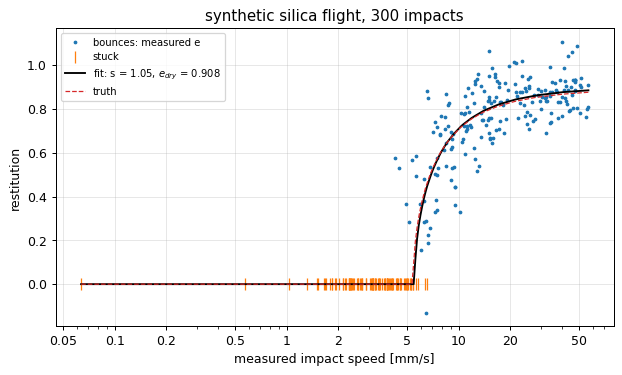

In [16]:
c = inv.curves(fit.gamma_scale, fit.e_dry, "silica", speeds=np.geomspace(flight.speed.min(), flight.speed.max(), 300))
ct = inv.curves(1.0, 0.90, "silica", speeds=c["v"])
fig, ax = plt.subplots(figsize=(8, 4.3))
h = flight.has_restitution
ax.semilogx(flight.speed[h] * 1e3, flight.restitution[h], ".", ms=4, label="bounces: measured e")
ax.semilogx(flight.speed[flight.stuck] * 1e3, np.zeros(flight.stuck.sum()), "|", ms=9, label="stuck")
ax.semilogx(c["v"] * 1e3, c["e"], "k-", label=f"fit: s = {fit.gamma_scale:.2f}, $e_{{dry}}$ = {fit.e_dry:.3f}")
ax.semilogx(ct["v"] * 1e3, ct["e"], "C3--", lw=1, label="truth")
ax.set_xlabel("measured impact speed [mm/s]"); nb.plain_log_axis(ax, "x"); ax.set_ylabel("restitution"); ax.legend(fontsize=8)
ax.set_title("synthetic silica flight, 300 impacts"); plt.show()

**Why this happens.** The fit finds $e_{dry}$ = 0.908 (1 sigma 0.902-0.913) and $s$ = 1.06 (1.01-1.11), 1.5 and
1.2 sigma from the truth (the two errors are correlated: a higher $e_{dry}$ needs a higher $\gamma$ for the same
sticking speed), and the sticking speed to 2 % (5.55 against 5.43 mm/s). The measured restitutions scatter widely
near the threshold (a few even above 1, from noise in both speeds), but the 211 bounces together pin the curve. The coverage test in
`tests/test_dolle_core_inverse.py` repeats this for 20 flights of 150 impacts: in the test run of 17 Nov 2026 each
1-sigma interval contained the truth in 65 % of the flights for $\gamma$ and 65 % for $e_{dry}$ (both together 50 %), and
the pulls (fit minus truth over the error bar) had spreads of 0.87 and 1.03 (1 expected) (68 % expected; run `pytest -s` to see the fractions, which
vary with the setup).

### 5.5 Stick/bounce alone cannot separate $\gamma$ and $e_{dry}$

The stick/bounce outcomes only see $v_{stick} = f(e_{dry})\,v_0(s) \propto f(e_{dry})\,s^{5/6}$. Every $(s, e_{dry})$ on
a curve of constant $f(e_{dry})\,s^{5/6}$ explains them equally well. The restitution of bounces depends on
$e_{dry}$ separately (it levels off at $e_{dry}$), so it cuts across that curve. The maps show $-\ln L$ above its
minimum for the same flight, without and with the measured restitutions.

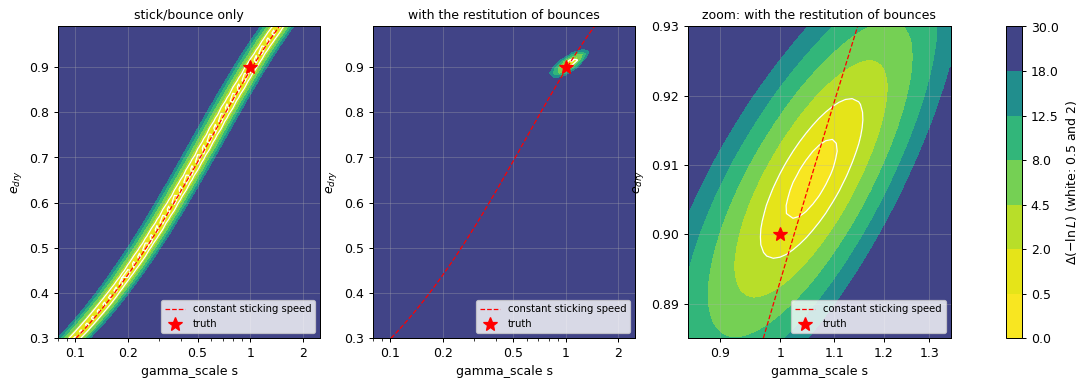

stick/bounce only:   gamma_scale = 0.100 (1 sigma 0.096 to 1.499), gamma = 0.0025 J/m^2
  e_dry       = 0.300 (1 sigma 0.300 to 0.990)
  sticking speed of two grains of 97.7 um diameter (radius 48.8 um): 5.48 mm/s
  interval reaches the search limit: e_dry low, e_dry high, gamma low, gamma high
  e_dry is not constrained: the best point is arbitrary, and the gamma interval only reflects e_dry in [0.30, 0.99]
with restitution : e_dry 0.902-0.913, gamma_scale 1.011-1.105


In [17]:
gs = np.geomspace(0.08, 2.5, 46)
ev = np.linspace(0.30, 0.99, 47)
maps = {"stick/bounce only": inv.nll_map(flight.without_restitution(), gs, ev),
        "with the restitution of bounces": inv.nll_map(flight, gs, ev)}
gz = np.geomspace(0.85, 1.35, 41)                                     # zoom around the best fit
ez = np.linspace(0.885, 0.93, 41)
maps_zoom = inv.nll_map(flight, gz, ez)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
levels = [0, 0.5, 2, 4.5, 8, 12.5, 18, 30]                             # n^2/2: 0, 1, 2, 3, ... sigma for one parameter
panels = list(maps.items()) + [("zoom: with the restitution of bounces", maps_zoom)]
for ax, (title, m) in zip(axes, panels):
    x_, y_ = (gz, ez) if title.startswith("zoom") else (gs, ev)
    d = m - m.min()
    cs = ax.contourf(x_, y_, np.minimum(d, 30), levels=levels, cmap="viridis_r")
    ax.contour(x_, y_, d, levels=[0.5, 2.0], colors="w", linewidths=1)
    ridge_s = fit.gamma_scale * (inv.threshold_factor(fit.e_dry) / inv.threshold_factor(y_)) ** 1.2
    ax.plot(ridge_s, y_, "r--", lw=1, label="constant sticking speed")
    ax.plot(1.0, 0.90, "r*", ms=12, label="truth")
    ax.set_xscale("log"); ax.set_xlim(x_[0], x_[-1]); ax.set_ylim(y_[0], y_[-1]); nb.plain_log_axis(ax, "x")
    ax.set_xlabel("gamma_scale s"); ax.set_ylabel("$e_{dry}$"); ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, loc="lower right")
plt.colorbar(cs, ax=axes, label="$\\Delta(-\\ln L)$ (white: 0.5 and 2)")
plt.show()
only = inv.fit(flight, use_restitution=False)
print("stick/bounce only:", only.summary().split("\n", 1)[1])
print(f"with restitution : e_dry {fit.e_dry_interval[0]:.3f}-{fit.e_dry_interval[1]:.3f}, "
      f"gamma_scale {fit.gamma_scale_interval[0]:.3f}-{fit.gamma_scale_interval[1]:.3f}")

**Why this happens.** Without restitutions the likelihood is a narrow valley along the curve of constant sticking
speed: $e_{dry}$ is unconstrained over the whole table (0.30-0.99). The printed best point (at the edge of the table)
is therefore arbitrary and means nothing, and the printed $\gamma$ interval (0.096-1.50 times the catalogue value) is NOT a measurement: it is
the stretch of the valley that the e_dry search range 0.30-0.99 allows, which is why `fit` now flags both ends of it
("gamma low", "gamma high"). Without restitutions $\gamma$ is unconstrained unless $e_{dry}$ is fixed. The sticking speed
itself is measured just as well (5.48 against 5.55 mm/s with the restitutions). With the restitutions the valley closes to a small ellipse around the
truth (right panel, zoomed). In the colour map the levels are $n^2/2$ = 0, 0.5, 2, 4.5, ...: the edges of 0, 1, 2,
3, ... sigma for one parameter at a time. (The joint 68 % and 95 % regions of the two parameters together are the
wider contours $\Delta(-\ln L)$ = 1.15 and 3.09.) **So the flight must record the restitution of bounces, not only
stick or bounce**, or else $\gamma$ can only be quoted for an assumed $e_{dry}$ (which is what
`dolle_sim.design.infer_surface_energy` does).

### 5.6 How many impacts are needed?

Target: $e_{dry}$ to ±0.05 and $\gamma$ to ±10 % (1 sigma). The cells fit synthetic flights of 25 to 400 impacts (3
seeds each) for two speed distributions: "wide" (0.3-10 $v_{stick}$, as above) and "gentle" (0.3-3 $v_{stick}$: a
release that keeps impacts close to the threshold); speed ranges are in units of the TRUE sticking speed. Errors are
profile intervals up to 200 impacts and Hessian errors at 400 (the first line checks that the two agree in the case
that used to fail: graphite, gentle, 50 impacts). A last cell repeats the wide case with a grain-to-grain spread of
adhesion (section 5.7).

In [18]:
chk = inv.make_synthetic_flight(50, "graphite", e_dry=0.70, speed_range=(0.3, 3.0), seed=500)
h_, p_ = inv.fit(chk, profile=False), inv.fit(chk)
print(f"check, graphite gentle 50 impacts: profile half-widths e_dry {p_.e_dry_halfwidth:.4f}, ln gamma "
      f"{p_.gamma_rel_halfwidth:.3f}; Hessian {h_.e_dry_halfwidth:.4f}, {h_.gamma_rel_halfwidth:.3f}")
Ns = (25, 50, 100, 200, 400)
need = {}


def impacts_needed(mat, e_true, design, rngv, sigma_ln_w=0.0, Ns=Ns, seeds=3, profile_up_to=200):
    """Median 1-sigma half-widths of e_dry and ln gamma over `seeds` synthetic flights per N; the smallest N that
    meets both targets.  Profile errors up to profile_up_to impacts, Hessian errors above."""
    he, hg = [], []
    for N in Ns:
        fs = [inv.fit(inv.make_synthetic_flight(N, mat, e_dry=e_true, speed_range=rngv, sigma_ln_w=sigma_ln_w,
                                                seed=500 + k), sigma_ln_w=sigma_ln_w, profile=N <= profile_up_to)
              for k in range(seeds)]
        he.append(np.median([f_.e_dry_halfwidth for f_ in fs])); hg.append(np.median([f_.gamma_rel_halfwidth for f_ in fs]))
    ok = [N for N, a, b in zip(Ns, he, hg) if a <= 0.05 and b <= 0.10]
    print(f"{mat:8s} {design:16s}: N = " + "  ".join(f"{N}: +-{a:.3f}/{b:.0%}" for N, a, b in zip(Ns, he, hg)))
    return ok[0] if ok else None


for design, rngv in (("wide", (0.3, 10.0)), ("gentle", (0.3, 3.0))):
    need[("silica", design)] = impacts_needed("silica", 0.90, design, rngv)

check, graphite gentle 50 impacts: profile half-widths e_dry 0.0138, ln gamma 0.067; Hessian 0.0131, 0.062


silica   wide            : N = 25: +-0.020/15%  50: +-0.015/13%  100: +-0.010/8%  200: +-0.007/6%  400: +-0.005/4%


silica   gentle          : N = 25: +-0.041/23%  50: +-0.028/14%  100: +-0.018/11%  200: +-0.014/7%  400: +-0.009/5%


In [19]:
for design, rngv in (("wide", (0.3, 10.0)), ("gentle", (0.3, 3.0))):
    need[("graphite", design)] = impacts_needed("graphite", 0.70, design, rngv)

graphite wide            : N = 25: +-0.013/8%  50: +-0.009/7%  100: +-0.006/4%  200: +-0.004/3%  400: +-0.003/2%


graphite gentle          : N = 25: +-0.019/14%  50: +-0.013/7%  100: +-0.010/5%  200: +-0.006/4%  400: +-0.005/3%


In [20]:
# grain-to-grain spread of adhesion: the simulator's 0.6 per grain is 0.6/sqrt(2) = 0.42 per grain-grain pair (5.7).
# Hessian errors only (profile fits with a spread are slow); test_adhesion_spread_pulls checks their pulls have unit spread.
for mat, e_true in (("silica", 0.90), ("graphite", 0.70)):
    need[(mat, "wide, spread 0.42")] = impacts_needed(mat, e_true, "wide, spread 0.42", (0.3, 10.0), sigma_ln_w=0.42,
                                                      Ns=(100, 200, 400), profile_up_to=0)
print("\nsmallest N tried with e_dry within +-0.05 and gamma within +-10 %:")
for k_, v_ in need.items():
    print(f"  {k_[0]:8s} {k_[1]:18s}: {v_}")

silica   wide, spread 0.42: N = 100: +-0.011/12%  200: +-0.008/8%  400: +-0.005/6%


graphite wide, spread 0.42: N = 100: +-0.009/8%  200: +-0.006/5%  400: +-0.004/4%

smallest N tried with e_dry within +-0.05 and gamma within +-10 %:
  silica   wide              : 100
  silica   gentle            : 200
  graphite wide              : 25
  graphite gentle            : 50
  silica   wide, spread 0.42 : 200
  graphite wide, spread 0.42 : 100


**Why this happens.** The errors shrink roughly as $1/\sqrt N$ (medians of only 3 flights, so single
entries scatter by 10-20 %). The $e_{dry}$ target (±0.05) is easy: even 25 impacts give about ±0.013-0.04. The
binding target is $\gamma$ to ±10 %: about 100 impacts for silica and 25-50 for graphite (whose speed errors are
relatively smaller) if all grains are alike. With the grain-to-grain spread of adhesion of the simulator's flight
configs (0.42 per grain-grain pair) the spread itself blurs the threshold: about 200 silica impacts and 100 graphite
impacts are needed (last cell; Hessian errors, whose pulls `tests/test_dolle_core_inverse.py` checks for that case).
Keeping all impacts below 3 $v_{stick}$ ("gentle") widens the $e_{dry}$ interval by about 1.5-2 times (silica:
±0.018 against ±0.010 at 100 impacts; silica then needs about 200 impacts for $\gamma$), and $e_{dry}$ then comes only
from the model's shape of $e(v)$ near the threshold, so it is more model-dependent. (An earlier version of this table
used curvature errors from the coarse speed integral, which were up to 2.7 times too small for graphite gentle; the
first line shows that the two kinds of error now agree there.) These counts are impacts that are filmed, tracked
and classified, with their restitution measured: the flight needs a release that produces **of order 100-200 such
impacts per material, ideally with some well above the threshold**.

### 5.7 What if the model itself is wrong?

The fit always returns numbers; the residuals say whether to believe them. Two ways the real grains could differ
from the model:

- **(a) Grain-to-grain spread of adhesion.** Real surfaces differ (roughness, contamination): the simulator's flight
  runs give each GRAIN an adhesion factor $\exp(0.6\,N(0,1))$ (`configs/mission_quarter_deck.json`, from the scatter of
  AFM adhesion on clean glass, Rush et al. 2018 as cited in PROVENANCE.md) and combine two grains as
  $\sqrt{a_ia_j}$ (`dolle_sim/simulation.py`). The fit's `sigma_ln_w` is the spread of $\ln w$ per PAIR, so for
  grain-grain impacts it is $0.6/\sqrt2$ = 0.42 (for grain-wall impacts it stays 0.6). Here the flight is made with
  0.42 and first fitted without it. (A grain that takes part in several impacts also makes their outcomes
  correlated; the likelihood treats impacts as independent.)
- **(b) Extra energy loss at low speed** that the model does not have (glass in vacuum loses more at 0.01 m/s than at
  1 m/s, Beger 2012; an "apparent adhesion" at low speed, Sorace, Louge, Crozier & Law 2009, Mech. Res. Commun. 36,
  364, with alumina, steel and acrylic spheres). Mimicked here by multiplying the true $e$ by $1 - 0.25\,e^{-(x-1)/2}$, $x = v/v_{stick}$ (an invented form,
  only for this test).

For each case: fit, then compare the observed stuck fraction and the mean restitution pull
$(e_m - \langle e_m\rangle)/\mathrm{sd}$ per speed bin with the prediction. The restitution $\chi^2$ is the sum of the
squared pulls over the $N$ bounces with a measured $e$; if the model is right it is $N \pm \sqrt{2N}$ (the mean and
spread of a $\chi^2$ distribution with $N$ degrees of freedom).

In [21]:
cases = {"model right": dict(),
         "(a) adhesion spread 0.42, fitted without": dict(sigma_ln_w=0.42),
         "(b) extra loss at low speed": dict(e_loss=lambda x: 1 - 0.25 * np.exp(-(x - 1) / 2))}
results = {}
for name, kw in cases.items():
    data = inv.make_synthetic_flight(400, "silica", gamma_scale=1.0, e_dry=0.90, seed=7, **kw)
    f_ = inv.fit(data)
    res = inv.residuals(data, f_.gamma_scale, f_.e_dry)
    results[name] = (data, f_, res)
    chi2, n = res["chi2_e"]
    print(f"{name:42s}: s = {f_.gamma_scale:.3f} ({f_.gamma_scale_interval[0]:.3f}-{f_.gamma_scale_interval[1]:.3f}), "
          f"e_dry = {f_.e_dry:.3f} ({f_.e_dry_interval[0]:.3f}-{f_.e_dry_interval[1]:.3f}); "
          f"restitution chi^2 {chi2:.0f} for {n} bounces (expected {n} +- {math.sqrt(2 * n):.0f})")
data_a = results["(a) adhesion spread 0.42, fitted without"][0]
fa = inv.fit(data_a, sigma_ln_w=0.42)
print(f"(a) refitted WITH sigma_ln_w = 0.42: s = {fa.gamma_scale:.3f} ({fa.gamma_scale_interval[0]:.3f}-"
      f"{fa.gamma_scale_interval[1]:.3f}), e_dry = {fa.e_dry:.3f} ({fa.e_dry_interval[0]:.3f}-{fa.e_dry_interval[1]:.3f}); "
      f"chi^2 {inv.residuals(data_a, fa.gamma_scale, fa.e_dry, sigma_ln_w=0.42)['chi2_e'][0]:.0f}")

model right                               : s = 1.011 (0.980-1.054), e_dry = 0.904 (0.899-0.909); restitution chi^2 242 for 266 bounces (expected 266 +- 23)


(a) adhesion spread 0.42, fitted without  : s = 1.050 (1.014-1.084), e_dry = 0.904 (0.899-0.909); restitution chi^2 318 for 265 bounces (expected 265 +- 23)


(b) extra loss at low speed               : s = 0.979 (0.945-1.016), e_dry = 0.875 (0.870-0.880); restitution chi^2 267 for 266 bounces (expected 266 +- 23)


(a) refitted WITH sigma_ln_w = 0.42: s = 1.008 (0.954-1.066), e_dry = 0.904 (0.898-0.909); chi^2 241


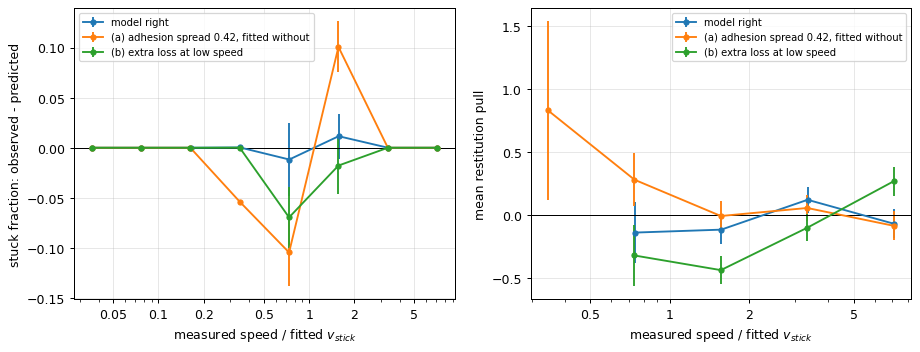

In [22]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
for k, (name, (data, f_, res)) in enumerate(results.items()):
    b = res["bins"]
    xm = [math.sqrt(r_["x_lo"] * r_["x_hi"]) for r_ in b]
    a1.errorbar(np.array(xm) * (1 + 0.03 * k), [r_["stuck_observed"] - r_["stuck_predicted"] for r_ in b],
                yerr=[r_["stuck_error"] for r_ in b], fmt="o-", ms=4, label=name)
    sel = [i for i, r_ in enumerate(b) if r_["n_e"] > 0]
    a2.errorbar(np.array(xm)[sel] * (1 + 0.03 * k), [b[i]["e_pull_mean"] for i in sel],
                yerr=[b[i]["e_pull_error"] for i in sel], fmt="o-", ms=4, label=name)
for ax, lab in ((a1, "stuck fraction: observed - predicted"), (a2, "mean restitution pull")):
    ax.axhline(0, color="k", lw=0.8); ax.set_xscale("log"); nb.plain_log_axis(ax, "x"); ax.set_xlabel("measured speed / fitted $v_{stick}$")
    ax.set_ylabel(lab); ax.legend(fontsize=8)
plt.show()

**Why this happens.** When the model is right, the residuals scatter around zero and $\chi^2$ = 242
for 266 bounces, about 1 sigma below the expected 266 ± 23. **(a)** A spread of adhesion smears the stick/bounce
transition: some pairs stick above the median threshold and some bounce below it. Fitted without the spread,
$\gamma$ comes out 5 % high (1.050, about 1.4 sigma), the stuck-fraction residuals swing negative below and positive
above $v_{stick}$ (the S-shape of a too-sharp model), the restitution pulls are positive near and below the threshold,
and $\chi^2$ rises to 318 for 265 bounces (2.3 sigma high). Refitting with the spread included (`sigma_ln_w=0.42`)
gives $s$ = 1.008 (0.954-1.066) and $\chi^2$ = 241. (The previous version of this cell used the per-grain 0.6 as the
per-pair spread, which overstates the effect.) **(b)** The injected loss only rescales the restitution of bounces
(the factor is at least 0.75, so never 0): it cannot change any stick/bounce outcome. Even so the fit pays for it:
$e_{dry}$ comes out 0.875, about 5 sigma below the truth, while $\chi^2$ (267 for 266) flags nothing. The binned
residuals do show it: restitution pulls negative near $v_{stick}$ and positive at the fastest impacts. The "fewer
sticks than predicted" just below the threshold is the fit compensating: a lower $e_{dry}$ means a larger $f$ and so a
higher predicted $v_{stick}$. (A real extra loss at low speed would also turn marginal bounces into sticks, which
this test leaves out.) With 400 impacts the binned pulls have errors of about 0.1-0.25, so the -0.3 to -0.4 pattern is
visible; at a flight's 100 impacts the errors double and a single bin is no longer significant, so pool the bins near
the threshold, or collect about 400 impacts, to have this check. **So look at the binned residuals, not only at
$\chi^2$.** A pattern like either is the signal to add physics (or a nuisance term such as `sigma_e_extra`) before
quoting the two numbers.

## What this means for DOLL-E

- **$e_{dry}$ is the largest assumed number in the sticking speeds.** Silica's literature range (0.80-0.97, central
  0.90) moves silica's sticking speed by a factor of 1.67 and puts the code's 0.85 a little low; graphite has no
  measurement at all, and its range (0.50-0.90) moves graphite's sticking speed by a factor of 3.2. The
  silica/graphite factor of about 6 could be anywhere from 3 to 16; graphite sticks more easily in every case.
- **The flight can measure $e_{dry}$ and $\gamma$ together**, but only if it records the restitution of bounces
  (exit speed as well as impact speed), not only stick or bounce. Stick/bounce alone measures the sticking speed, i.e.
  only the product $f(e_{dry})\,\gamma^{5/6}$.
- **How many impacts.** About 100 measured impacts per material pin $e_{dry}$ to about ±0.01-0.02 and
$\gamma$ to about ±10 % if all grains are alike (silica; graphite needs fewer); with the grain-to-grain spread of
adhesion that the flight configs assume, about 200 for silica and 100 for graphite (section 5.6). Impacts at several times the sticking speed read $e_{dry}$ almost
  directly; a release that keeps every impact close to the threshold gives wider and more model-dependent $e_{dry}$
  intervals.
- **Requirements this puts on the flight** (the box at the top): speeds from two camera views (a single camera
  makes speeds about 21 % low and $\gamma$ about 25 % low unless each impact is corrected); at least 6 clean frames
  before and after each impact (ASSUMED design camera); most impacts near the sticking speed, from a gentle release
  (docs/OVERVIEW.md, section 7), plus a tail at 5-10 times it (3-6 cm/s for silica, 0.2-0.4 m/s for graphite).
- **Measure $e_{dry}$ on the ground first** (the flight powders dropped in vacuum on a polished plate of the same
  material at 0.1-1 m/s). The flight then tests the model, with the residuals of section 5.7 as the check. Comparing
  the ground-measured $e_{dry}$ with the flight-fitted one also tests the model's damping in the stretched neck
  (section 2): if they disagree while the residuals look clean, the neck damping is wrong, not the ground
  measurement.
- `examples/fit_flight_data.py` fits a CSV of filmed impacts (format in `dolle_core/inverse.py`, `CSV_HELP`); with
  no argument it fits a synthetic example.

## What to remember

- $e_{dry}$ is the restitution of a non-sticky impact. The code turns it into a damping force
  $c_d\sqrt a\,\dot\delta$ calibrated so that a non-sticky impact returns $e_{dry}$ at every speed (to 1e-3).
- $v_{stick} = f(e_{dry})\,v_0$ with $f$ = 1.39 at 0.90, 1.61 at 0.85, 2.46 at 0.70; at 0.85 the damping takes
  about 62 % of the incoming energy at the sticking speed, not 28 %.
- $e(v)$ depends only on $v/v_0$ and $e_{dry}$; it reaches $e_{dry}$ slowly (0.85-0.96 of it at 5 $v_{stick}$).
- Stick/bounce data alone see only $f(e_{dry})\,s^{5/6}$; restitutions of bounces separate $e_{dry}$ from $\gamma$.
- Always look at the residuals: a model that is wrong still returns numbers.

## Check it yourself

Change the true values, the number of impacts or the speed spread below (`speed_range` is in units of the TRUE
sticking speed, so changing the true values does not move the window). **Predict first**: will the 1-sigma
half-width of $e_{dry}$ be above or below 0.05? Does halving the number of impacts widen it by $\sqrt2$? What happens
to $\gamma$'s interval if you set `restitution_fraction=0` (no measured restitutions)?

In [23]:
my = inv.make_synthetic_flight(n=120, material="graphite", gamma_scale=2.0, e_dry=0.6, speed_range=(0.5, 4.0),
                               restitution_fraction=1.0, seed=42)
print(inv.fit(my).summary())
print(f"notebook run time: {time.perf_counter() - T0:.0f} s")

graphite-graphite: 120 impacts (43 stuck, 77 bounces with e), 0 dropped (above 0.9 v_yield)
  gamma_scale = 2.052 (1 sigma 1.970 to 2.142), gamma = 0.1539 J/m^2
  e_dry       = 0.607 (1 sigma 0.600 to 0.614)
  sticking speed of two grains of 97.7 um diameter (radius 48.8 um): 92.67 mm/s
notebook run time: 304 s
